# Chapitre 5 - Exercices 5.1 à 5.6

Ce notebook traite les six premiers exercices du chapitre 5, centrés sur les formats
d'encodage et l'évolution des schémas :

- **5.1** : compter les octets à la main dans chaque format (calcul) ;
- **5.2** : varints, zigzag et encodage différentiel d'horodatages (calcul et
  mini-lab) ;
- **5.3** : grands identifiants et Base64, les pièges des formats textuels (calcul) ;
- **5.4** : écrire un vérificateur d'évolution de schémas Protocol Buffers (mini-lab) ;
- **5.5** : décoder un enregistrement Avro à la main et prédire la résolution
  (raisonnement) ;
- **5.6** : registre de schémas, compatibilité transitive et rétention (raisonnement
  et code).

In [1]:
import json
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import encoding as E
from ddia.encoding import PbField, PbMessage
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 120)
rng = np.random.default_rng(0)

## Exercice 5.1 : compter les octets à la main

**Énoncé.** On encode l'enregistrement
`{"userName": "Zoé", "favoriteNumber": -200, "interests": ["vélo"]}` (attention : `é` est
un caractère non ASCII).

1. Combien d'octets en JSON compact ? en MessagePack ?
2. Combien d'octets en Protocol Buffers avec le schéma du cours (`int64
   favorite_number = 2`) ? Et si le champ est déclaré `sint64` ?
3. Combien d'octets en Avro avec le schéma `Person` du cours ?
4. Classer les formats et expliquer l'écart entre `int64` et `sint64`.

**Rappels.** UTF-8 code `é` sur 2 octets. MessagePack : chaîne courte = 1 octet
(`0xa0 | longueur`) + contenu ; entier de -32 768 à 32 767 hors des plages courtes : 1
octet de type + 2. Protobuf : clé d'un octet (numéro < 16), longueurs et entiers en
varint ; un `int64` négatif est écrit en complément à deux sur 64 bits, donc en 10 octets
de varint ; `sint64` utilise le zigzag. Avro : longueurs et entiers en zigzag, indice de
branche d'union, tableau = compte + éléments + 0 (cours 1 à 3, sections *Binary encoding*,
*Protocol Buffers*, *Avro*).

**Solution.**

*1. JSON.* `{"userName":"Zoé","favoriteNumber":-200,"interests":["vélo"]}` compte 61
caractères, dont 2 `é` de 2 octets : **63 octets**. *MessagePack* : en-tête de map (1) ;
`userName` (1 + 8) ; `Zoé` (1 + 4) ; `favoriteNumber` (1 + 14) ; -200 ne tient pas dans
l'entier négatif court (-32 à -1) : `0xd1` + 2 octets (3) ; `interests` (1 + 9) ; tableau
d'un élément (1) ; `vélo` (1 + 5). Total : 1 + 9 + 5 + 15 + 3 + 10 + 1 + 6 = **50 octets**.

*2. Protobuf.* Champ 1 : clé + longueur + 4 octets = 6. Champ 2 en `int64` : -200 en
complément à deux a ses bits de poids fort à 1, le varint fait **10 octets**, plus la
clé : 11. Champ 3 : clé + longueur + 5 = 7. Total **24 octets**. En `sint64` : zigzag(-200)
= 399, qui tient sur 2 octets de varint (399 < 16 384) : 1 + 2 = 3, total **16 octets**.

*3. Avro.* Longueur 4 en zigzag (1 octet `08`) + 4 octets ; indice de branche 1 (1 octet) +
zigzag(-200) = 399 sur 2 octets ; tableau : compte (1) + longueur (1) + 5 octets + fin
(1). Total : 5 + 3 + 8 = **16 octets**.

*4.* Avro (16) = Protobuf `sint64` (16) < Protobuf `int64` (24) < MessagePack (50) < JSON
(63). Un `int64` négatif coûte toujours 10 octets en protobuf : pour un champ qui peut être
négatif, `sint64` est le bon choix.

**Vérification.**

In [2]:
zoe = {"userName": "Zoé", "favoriteNumber": -200, "interests": ["vélo"]}
PB_S = PbMessage("Person", [PbField("user_name", 1, "string"), PbField("favorite_number", 2, "sint64"),
                            PbField("interests", 3, "string", repeated=True)])
tailles = {"JSON compact": len(E.json_bytes(zoe)), "MessagePack": len(E.msgpack_encode(zoe)),
           "Protobuf (int64)": len(E.pb_encode(E.to_pb_record(zoe), E.PERSON_PB)),
           "Protobuf (sint64)": len(E.pb_encode(E.to_pb_record(zoe), PB_S)),
           "Avro": len(E.avro_encode(zoe, E.PERSON_AVRO))}
print(tailles)

{'JSON compact': 63, 'MessagePack': 50, 'Protobuf (int64)': 24, 'Protobuf (sint64)': 16, 'Avro': 16}


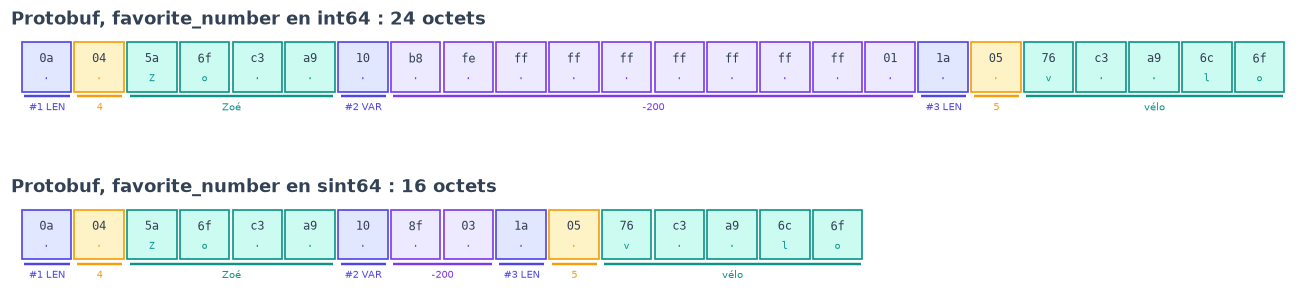

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(12, 3.6))
for ax, (nom, sch) in zip(axes, [("int64", E.PERSON_PB), ("sint64", PB_S)]):
    tr = []
    b = E.pb_encode(E.to_pb_record(zoe), sch, tr)
    E.draw_byte_map(b, tr, title=f"Protobuf, favorite_number en {nom} : {len(b)} octets", per_row=24, ax=ax)
plt.tight_layout(); plt.show()

La carte d'octets montre les 10 octets `b8 fe ff ... ff 01` du `int64` négatif, réduits à
`8f 03` en `sint64`.

> **À retenir.** Compter les octets, c'est additionner en-têtes, longueurs et valeurs ;
> les noms de champs dominent les formats sans schéma, et le choix du type entier
> (complément à deux ou zigzag) peut multiplier par cinq la taille d'un nombre négatif.

## Exercice 5.2 : varints, zigzag et encodage différentiel

**Énoncé.** Un capteur envoie des horodatages en millisecondes (ordre de grandeur
$1{,}5 \cdot 10^{12}$), un toutes les 1 000 ms environ (gigue de ±50 ms).

1. Combien d'octets un varint utilise-t-il pour une valeur de $b$ bits ? Pour un
   horodatage ?
2. On transmet des lots de 1 000 horodatages dans un champ `repeated` compacté. Comparer
   trois encodages : `fixed64`, varint des valeurs brutes, varint (zigzag) des **écarts**
   successifs (le premier en valeur absolue).
3. Si l'écart moyen est $d$ millisecondes, à partir de quel $d$ l'encodage différentiel
   perd-il son avantage sur `fixed64` ?

**Rappels.** Un varint transporte 7 bits utiles par octet ; zigzag : $z = 2n$ si
$n \ge 0$, $-2n - 1$ sinon (cours 2, section 2). Un champ `repeated` compacté écrit une
clé, une longueur, puis les valeurs à la suite.

**Solution.**

*1.* $\max(1, \lceil b / 7 \rceil)$ octets. $1{,}5 \cdot 10^{12} < 2^{41}$ ($\approx 2{,}2
\cdot 10^{12}$) : 41 bits, donc $\lceil 41/7 \rceil = 6$ octets.

*2.* `fixed64` : 8 octets par valeur, soit environ 8 000 octets. Varint brut : 6 octets par
valeur, environ 6 000. Différentiel : un écart d'environ 1 000 vaut, en zigzag, environ
2 000, soit 11 bits, donc 2 octets ; plus 6 octets pour la première valeur : environ
2 000 octets, **quatre fois moins** que `fixed64`.

*3.* L'écart zigzagué vaut $2d$ ; il faut $\lceil \log_2(2d+1)/7 \rceil$ octets. Il reste
sous 8 octets tant que $2d < 2^{56}$, c'est-à-dire toujours en pratique ; mais il ne bat
plus le varint brut (6 octets) que si $2d < 2^{35}$, soit $d$ inférieur à environ 200 jours.
L'encodage différentiel est donc gagnant dès que les valeurs sont **triées et proches**.

{'fixed64': 8003, 'varint brut': 6003, 'varint des écarts (zigzag)': 2007}


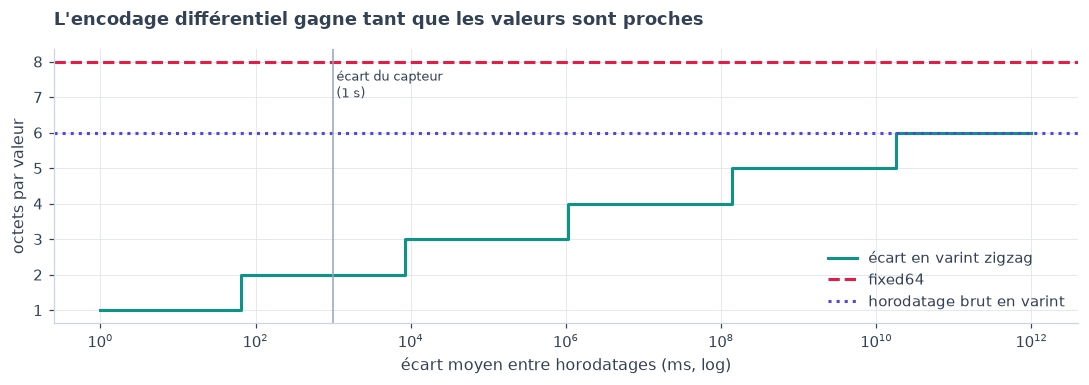

In [4]:
t0 = 1_546_300_800_000
ts = t0 + np.cumsum(rng.integers(950, 1051, 1000))
deltas = np.diff(np.concatenate([[0], ts]))
s_u64 = PbMessage("Lot", [PbField("t", 1, "uint64", repeated=True)])
s_f64 = PbMessage("Lot", [PbField("t", 1, "fixed64", repeated=True)])
s_s64 = PbMessage("Lot", [PbField("t", 1, "sint64", repeated=True)])
lots = {"fixed64": len(E.pb_encode({"t": [int(x) for x in ts]}, s_f64)),
        "varint brut": len(E.pb_encode({"t": [int(x) for x in ts]}, s_u64)),
        "varint des écarts (zigzag)": len(E.pb_encode({"t": [int(x) for x in deltas]}, s_s64))}
assert np.array_equal(np.cumsum(E.pb_decode(E.pb_encode({"t": [int(x) for x in deltas]}, s_s64), s_s64)["t"]), ts)
print(lots)

d = np.logspace(0, 12, 200)
taille = [E.uvarint_size(E.zigzag_encode(int(x))) for x in d]
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.step(d, taille, where="post", color=TEAL, label="écart en varint zigzag")
ax.axhline(8, color=ROSE, ls="--", label="fixed64")
ax.axhline(6, color=INDIGO, ls=":", label="horodatage brut en varint")
ax.axvline(1000, color=GRAY, lw=1); ax.text(1100, 7.0, "écart du capteur\n(1 s)", fontsize=8.5, color=SLATE)
ax.set_xscale("log"); ax.set_xlabel("écart moyen entre horodatages (ms, log)"); ax.set_ylabel("octets par valeur")
ax.set_title("L'encodage différentiel gagne tant que les valeurs sont proches")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

Mesuré : 8 003, 6 003 et 2 007 octets (les 3 octets d'en-tête du champ compacté et les 6
octets de la première valeur compris). C'est la même idée que la compression des colonnes
triées (chapitre 4).

> **À retenir.** Un varint coûte $\lceil b/7 \rceil$ octets ; sur des valeurs triées,
> encoder les écarts (en zigzag) plutôt que les valeurs divise la taille par trois ou
> quatre.

## Exercice 5.3 : grands identifiants et Base64

**Énoncé.** Un service attribue des identifiants de 64 bits à la manière de Snowflake :
`id = (t << 22) | (machine << 12) | séquence`, où $t$ est le nombre de millisecondes
écoulées depuis une époque propre au service.

1. Au bout de combien de temps après l'époque les identifiants dépassent-ils $2^{53}$ ?
2. Un client JavaScript lit les identifiants comme des nombres JSON (doubles). Pour un
   identifiant tiré uniformément dans $[2^{62}, 2^{63}[$, quelle est la probabilité qu'il
   soit relu exactement ? Quelle erreur maximale ?
3. Une API renvoie des vignettes d'images de 30 Kio en Base64 dans du JSON. Quel est le
   surcoût en octets pour 1 million de vignettes par jour ?

**Rappels.** Un double représente exactement tous les entiers jusqu'à $2^{53}$ ; entre
$2^{k}$ et $2^{k+1}$, l'écart entre doubles consécutifs vaut $2^{k-52}$. Base64 : 4
caractères pour 3 octets, avec remplissage (cours 1, section 4).

**Solution.**

*1.* $t \cdot 2^{22} > 2^{53} \iff t > 2^{31}$ ms $\approx 2{,}15 \cdot 10^9$ ms, soit
**24,9 jours**. Quelques semaines après la mise en service, plus aucun identifiant n'est
représentable exactement.

*2.* Dans $[2^{62}, 2^{63}[$, l'écart entre doubles vaut $2^{62-52} = 1\,024$ : seul un
identifiant multiple de 1 024 survit, probabilité **1/1 024** (environ 0,1 %). L'arrondi au
plus proche fait une erreur d'au plus **512**. C'est pourquoi les API concernées renvoient
aussi l'identifiant sous forme de chaîne.

*3.* $30 \times 1\,024 = 30\,720$ octets donnent $4 \lceil 30\,720 / 3 \rceil = 40\,960$
caractères : 10 240 octets de plus par vignette, soit **10,24 Go par jour** (un tiers de
plus), avant compression HTTP éventuelle.

In [5]:
print(f"1. dépassement de 2^53 après {2 ** 31 / 1000 / 86400:.1f} jours")
ids = rng.integers(2 ** 62, 2 ** 63 - 1, 200_000, dtype=np.int64)
relus = np.array([int(float(int(x))) for x in ids], dtype=object)
exacts = np.mean([int(a) == b for a, b in zip(ids, relus)])
erreur = max(abs(int(a) - b) for a, b in zip(ids[:20000], relus[:20000]))
print(f"2. relus exactement : {exacts:.4%} (théorie {1 / 1024:.4%}) ; erreur maximale observée : {erreur}")
import base64
print(f"3. surcoût par vignette : {len(base64.b64encode(bytes(30 * 1024))) - 30 * 1024} octets ; "
      f"par jour : {(len(base64.b64encode(bytes(30 * 1024))) - 30 * 1024) * 1e6 / 1e9:.2f} Go")

1. dépassement de 2^53 après 24.9 jours
2. relus exactement : 0.0895% (théorie 0.0977%) ; erreur maximale observée : 512
3. surcoût par vignette : 10240 octets ; par jour : 10.24 Go


> **À retenir.** Des identifiants de 64 bits dépassent $2^{53}$ presque immédiatement ;
> un client qui les lit en double les corrompt (erreur jusqu'à 512 vers $2^{62}$). Base64
> ajoute un tiers au volume des données binaires.

## Exercice 5.4 : un vérificateur d'évolution de schémas Protocol Buffers

**Énoncé.** Écrire une fonction `pb_lint(ancien, nouveau)` qui compare deux versions d'un
message Protocol Buffers et signale :

- un champ dont le **numéro a changé** (même nom, numéro différent) ;
- un numéro **réutilisé** avec un autre nom ou un autre type ;
- un champ **supprimé** dont le numéro n'est pas réservé ;
- un changement de type qui change le **type d'onde** (valeur invisible) ou qui
  **rétrécit/élargit** un entier, ou passe d'un entier en complément à deux au zigzag ;
- un numéro **réservé** réutilisé.

L'appliquer à la revue de code ci-dessous et dire quelles modifications accepter.

In [6]:
ancien = PbMessage("Commande", [
    PbField("id", 1, "int64"), PbField("client", 2, "string"), PbField("montant_centimes", 3, "int32"),
    PbField("note", 4, "string"), PbField("articles", 5, "string", repeated=True)], reserved=[6])
nouveau = PbMessage("Commande", [
    PbField("id", 1, "int64"), PbField("client_id", 2, "string"),          # renommé
    PbField("montant_centimes", 3, "int64"),                               # élargi
    PbField("remise", 4, "sint32"),                                        # numéro 4 réutilisé
    PbField("articles", 7, "string", repeated=True),                       # numéro changé
    PbField("devise", 6, "string")])                                       # numéro réservé réutilisé
print(nouveau.to_proto())

message Commande {
    int64 id = 1;
    string client_id = 2;
    int64 montant_centimes = 3;
    sint32 remise = 4;
    repeated string articles = 7;
    string devise = 6;
}


**Rappels.** Le numéro donne son sens à la donnée ; renommer est sûr ; ne jamais changer
ni réutiliser un numéro ; un type d'onde différent rend la valeur invisible ; un entier
élargi est tronqué par l'ancien lecteur (cours 2, sections 4 à 6).

**Solution.** On indexe les champs par numéro et par nom, puis on compare.

In [7]:
ENTIERS_C2 = {"int32", "int64", "uint32", "uint64"}

def pb_lint(old, new):
    probs = []
    o_tag, n_tag = old.by_tag(), new.by_tag()
    o_nom = {f.name: f for f in old.fields}
    for f in new.fields:
        if f.tag in old.reserved:
            probs.append(("erreur", f"n° {f.tag} ({f.name}) : numéro réservé réutilisé"))
        if f.name in o_nom and o_nom[f.name].tag != f.tag:
            probs.append(("erreur", f"{f.name} : numéro changé {o_nom[f.name].tag} -> {f.tag}"))
        g = o_tag.get(f.tag)
        if g is None:
            continue
        if g.type != f.type:
            if E.WIRE_TYPE.get(g.type) != E.WIRE_TYPE.get(f.type):
                probs.append(("erreur", f"n° {f.tag} : type d'onde changé ({g.type} -> {f.type}), valeur invisible"))
            elif {g.type, f.type} <= ENTIERS_C2:
                probs.append(("attention", f"n° {f.tag} : {g.type} -> {f.type}, troncature possible chez le lecteur le plus étroit"))
            else:
                probs.append(("erreur", f"n° {f.tag} : {g.type} -> {f.type}, mêmes octets interprétés autrement"))
        if g.name != f.name:
            sev = "info" if g.type == f.type else "erreur"
            probs.append((sev, f"n° {f.tag} : renommé {g.name} -> {f.name}" + (" (sûr)" if sev == "info" else " avec un autre type : réutilisation ?")))
    for g in old.fields:
        if g.tag not in n_tag and g.tag not in new.reserved:
            probs.append(("attention", f"n° {g.tag} ({g.name}) supprimé sans être réservé"))
    return pd.DataFrame(probs, columns=["gravité", "problème"])

pb_lint(ancien, nouveau)

,gravité,problème
0,info,n° 2 : renommé client -> client_id (sûr)
1,attention,"n° 3 : int32 -> int64, troncature possible chez le lecteur le plus étroit"
2,erreur,"n° 4 : type d'onde changé (string -> sint32), valeur invisible"
3,erreur,n° 4 : renommé note -> remise avec un autre type : réutilisation ?
4,erreur,articles : numéro changé 5 -> 7
5,erreur,n° 6 (devise) : numéro réservé réutilisé
6,attention,n° 5 (articles) supprimé sans être réservé


Verdict de la revue : accepter le **renommage** `client -> client_id` ; refuser la
réutilisation du numéro 4 (`note`, chaîne, devenue `remise`, entier : les anciennes notes
deviendraient invisibles et les remises illisibles par les anciens lecteurs), le
**changement de numéro** de `articles` (toutes les anciennes commandes perdraient leurs
articles) et la réutilisation du numéro **réservé** 6. L'élargissement de
`montant_centimes` est acceptable si aucun ancien lecteur ne reçoit de montant supérieur à
$2^{31}$ centimes (21 millions d'euros), sinon troncature. Version corrigée et
vérification :

In [8]:
corrige = PbMessage("Commande", [
    PbField("id", 1, "int64"), PbField("client_id", 2, "string"), PbField("montant_centimes", 3, "int64"),
    PbField("articles", 5, "string", repeated=True), PbField("remise", 8, "sint32"),
    PbField("devise", 9, "string")], reserved=[4, 6])
print(pb_lint(ancien, corrige))
vieille = E.pb_encode({"id": 1, "client": "c-9", "montant_centimes": 1999, "note": "fragile",
                       "articles": ["livre", "lampe"]}, ancien)
print("ancienne commande lue avec le schéma corrigé :", E.pb_decode(vieille, corrige, keep_unknown=False))
print("ancienne commande lue avec le schéma proposé :", E.pb_decode(vieille, nouveau, keep_unknown=False))

     gravité  \
0       info   
1  attention   

                                                                    problème  
0                                   n° 2 : renommé client -> client_id (sûr)  
1  n° 3 : int32 -> int64, troncature possible chez le lecteur le plus étroit  
ancienne commande lue avec le schéma corrigé : {'id': 1, 'client_id': 'c-9', 'montant_centimes': 1999, 'articles': ['livre', 'lampe'], 'remise': 0, 'devise': ''}
ancienne commande lue avec le schéma proposé : {'id': 1, 'client_id': 'c-9', 'montant_centimes': 1999, 'remise': 0, 'articles': [], 'devise': ''}


Avec le schéma proposé, l'ancienne commande perd ses articles et sa note ; avec le schéma
corrigé, tout ce qui existait reste lisible et les nouveaux champs prennent leur défaut.

> **À retenir.** Les règles d'évolution de protobuf se vérifient mécaniquement : un
> « linter » de schémas dans la chaîne d'intégration continue attrape numéros changés ou
> réutilisés et changements de type dangereux avant qu'ils n'atteignent la production.

## Exercice 5.5 : décoder un enregistrement Avro à la main

**Énoncé.** Un fichier contient l'enregistrement suivant (en hexadécimal), écrit avec le
schéma de l'écrivain `W` :

```
02 0a 41 6c 69 63 65 04 0a 76 c3 a9 6c 6f 08 6a 61 7a 7a 00 01
```

```json
{"type": "record", "name": "Membre", "fields": [
  {"name": "id",    "type": "int"},
  {"name": "nom",   "type": "string"},
  {"name": "tags",  "type": {"type": "array", "items": "string"}},
  {"name": "actif", "type": "boolean"}]}
```

1. Décoder l'enregistrement octet par octet.
2. Un lecteur utilise le schéma `R` ci-dessous. Que lit-il ?
3. Pourquoi le lecteur ne pourrait-il pas déclarer `"type": ["string", "null"], "default": null`
   pour un nouveau champ ?
4. Un bit s'inverse sur le disque et le 9e octet (`0a`) devient `06`. Que se passe-t-il au
   décodage ? Avro peut-il détecter la corruption ?

In [9]:
W5 = {"type": "record", "name": "Membre", "fields": [
    {"name": "id", "type": "int"}, {"name": "nom", "type": "string"},
    {"name": "tags", "type": {"type": "array", "items": "string"}}, {"name": "actif", "type": "boolean"}]}
R5 = {"type": "record", "name": "Membre", "fields": [
    {"name": "nom", "type": "string"},
    {"name": "identifiant", "aliases": ["id"], "type": "double"},
    {"name": "email", "type": ["null", "string"], "default": None},
    {"name": "tags", "type": {"type": "array", "items": "string"}}]}
print(json.dumps(R5, ensure_ascii=False))

{"type": "record", "name": "Membre", "fields": [{"name": "nom", "type": "string"}, {"name": "identifiant", "aliases": ["id"], "type": "double"}, {"name": "email", "type": ["null", "string"], "default": null}, {"name": "tags", "type": {"type": "array", "items": "string"}}]}


**Rappels.** Avro : `int`/`long` et longueurs en zigzag varint ; chaîne = longueur + UTF-8 ;
tableau = blocs (compte, éléments) terminés par 0 ; booléen = 1 octet. Résolution :
appariement par nom ou alias, promotion `int -> double`, champ inconnu du lecteur ignoré,
champ absent chez l'écrivain rempli par le défaut du lecteur (cours 3, sections 1 à 3).

**Solution.**

*1.* `02` : zigzag 2 -> **id = 1**. `0a` : longueur 5 -> `41 6c 69 63 65` = **« Alice »**.
`04` : bloc de **2** éléments ; `0a` : longueur 5 (en **octets** : `é` en prend 2) ->
`76 c3 a9 6c 6f` = « vélo » ; `08` : longueur 4 -> `6a 61 7a 7a` = « jazz » ; `00` : fin du
tableau ; `01` : **actif = true**. Soit `{"id": 1, "nom": "Alice", "tags": ["vélo",
"jazz"], "actif": true}`.

*2.* Le lecteur obtient `{"nom": "Alice", "identifiant": 1.0, "email": None, "tags":
["vélo", "jazz"]}` : `identifiant` est apparié à `id` par l'alias et promu en `double` ;
`email` prend son défaut ; `actif`, inconnu du lecteur, est ignoré.

*3.* Le défaut d'une union doit être du type de la **première** branche : `null` comme
défaut exige `["null", "string"]`.

*4.* Avec `06` (longueur 3), le décodeur lit `76 c3 a9` (« vé »), puis prend `6c` pour la
longueur de la chaîne suivante (zigzag 54) : il cherche 54 octets là où il n'en reste que
10. Ici l'erreur est détectée par chance (données tronquées) ; mais une corruption qui
laisse des octets « plausibles » produirait des valeurs fausses sans erreur : Avro n'a ni
balises ni somme de contrôle par enregistrement (le fichier conteneur s'appuie sur ses
marqueurs de synchronisation, et l'on ajoute des sommes de contrôle au niveau du stockage).

In [10]:
correct = bytes.fromhex("02 0a 41 6c 69 63 65 04 0a 76 c3 a9 6c 6f 08 6a 61 7a 7a 00 01")
fautif = correct[:8] + b"\x06" + correct[9:]
for nom, b in [("octets de l'énoncé", correct), ("9e octet corrompu (0a -> 06)", fautif)]:
    try:
        print(f"{nom} : {E.avro_decode(b, W5)}")
    except (E.AvroError, ValueError) as exc:
        print(f"{nom} : échec ({exc})")
print("lu avec R :", E.avro_decode(correct, W5, R5))
assert E.avro_encode({"id": 1, "nom": "Alice", "tags": ["vélo", "jazz"], "actif": True}, W5) == correct

octets de l'énoncé : {'id': 1, 'nom': 'Alice', 'tags': ['vélo', 'jazz'], 'actif': True}
9e octet corrompu (0a -> 06) : échec (données tronquées)
lu avec R : {'nom': 'Alice', 'identifiant': 1.0, 'email': None, 'tags': ['vélo', 'jazz']}


Le décodage de l'énoncé donne bien l'enregistrement attendu (que l'encodeur du module
reproduit octet pour octet), et la version corrompue échoue faute d'octets.

> **À retenir.** Décoder de l'Avro, c'est suivre le schéma de l'écrivain champ par champ ;
> une seule longueur fausse décale toute la suite. La résolution vers le lecteur se fait
> par nom (ou alias), avec promotions et valeurs par défaut.

## Exercice 5.6 : registre de schémas, compatibilité transitive et rétention

**Énoncé.** Un sujet de messages conserve ses messages **30 jours**, et certains
consommateurs relisent l'historique depuis le début. On fait évoluer le schéma ainsi :

- v1 : `{id: long, email: string}` ;
- v2 : `{id: long, email: string (défaut "")}` (on ajoute un défaut) ;
- v3 : `{id: long}` (on supprime `email`) ;
- v4 : `{id: long, telephone: string}` (champ ajouté **sans** défaut).

1. Pour chaque version, le registre l'accepte-t-il en mode `BACKWARD` ? `FORWARD` ?
   `FORWARD_TRANSITIVE` ? `BACKWARD_TRANSITIVE` ?
2. Un consommateur v1 (pas encore mis à jour) lit des messages v3 : que se passe-t-il ?
3. Un nouveau consommateur v4 relit les 30 jours d'historique : que se passe-t-il ? Quel
   mode faut-il exiger pour ce sujet ?

**Rappels.** `BACKWARD` : le nouveau schéma lit les données du précédent ; `FORWARD` :
l'ancien schéma lit les données du nouveau ; `_TRANSITIVE` : par rapport à **toutes** les
versions antérieures (cours 3, section 4).

**Solution.**

*1.* v2 ne fait qu'ajouter un défaut : compatible partout. v3 supprime `email` : un
lecteur v2 qui lit du v3 trouve le défaut (FORWARD ok par rapport à v2) ; mais un lecteur
v1 n'a pas de défaut (FORWARD_TRANSITIVE refusé). En BACKWARD, v3 lit sans problème les
anciennes données (il ignore `email`). v4 ajoute `telephone` sans défaut : v4 ne sait pas
lire les données v1 à v3 (BACKWARD et BACKWARD_TRANSITIVE refusés), alors que les anciens
lecteurs ignorent le champ (FORWARD acceptable, et FORWARD_TRANSITIVE seulement si v3 l'a
été, ce qui n'est pas le cas).

*2.* Le consommateur v1 exige `email`, absent des messages v3 et sans défaut chez lui :
erreur de résolution. Le mode `FORWARD` (non transitif) a laissé passer v3 parce qu'il
ne regardait que v2.

*3.* Le consommateur v4 relit des messages v1 à v3 sans `telephone` et sans défaut :
échec. Un sujet dont on relit l'historique exige que le **dernier** schéma sache lire
**toutes** les versions encore présentes : `BACKWARD_TRANSITIVE` (et `FULL_TRANSITIVE` si
d'anciens consommateurs doivent aussi lire les nouveaux messages).

In [11]:
def s(*fields):
    return {"type": "record", "name": "Contact", "fields": list(fields)}
V = {"v1": s({"name": "id", "type": "long"}, {"name": "email", "type": "string"}),
     "v2": s({"name": "id", "type": "long"}, {"name": "email", "type": "string", "default": ""}),
     "v3": s({"name": "id", "type": "long"}),
     "v4": s({"name": "id", "type": "long"}, {"name": "telephone", "type": "string"})}
rows = {}
for mode in ["BACKWARD", "FORWARD", "FORWARD_TRANSITIVE", "BACKWARD_TRANSITIVE", "FULL_TRANSITIVE"]:
    reg = E.SchemaRegistry(mode)
    col = {}
    for nom, sch in V.items():
        pb = reg.check("contact", sch)
        col[nom] = "acceptée" if not pb else "refusée"
        reg.subjects.setdefault("contact", []).append(len(reg.schemas) + 1)   # on l'enregistre quand même
        reg.schemas[len(reg.schemas) + 1] = sch
    rows[mode] = col
verdicts = pd.DataFrame(rows)
verdicts

,BACKWARD,FORWARD,FORWARD_TRANSITIVE,BACKWARD_TRANSITIVE,FULL_TRANSITIVE
v1,acceptée,acceptée,acceptée,acceptée,acceptée
v2,acceptée,acceptée,acceptée,acceptée,acceptée
v3,acceptée,acceptée,refusée,acceptée,refusée
v4,refusée,acceptée,refusée,refusée,refusée


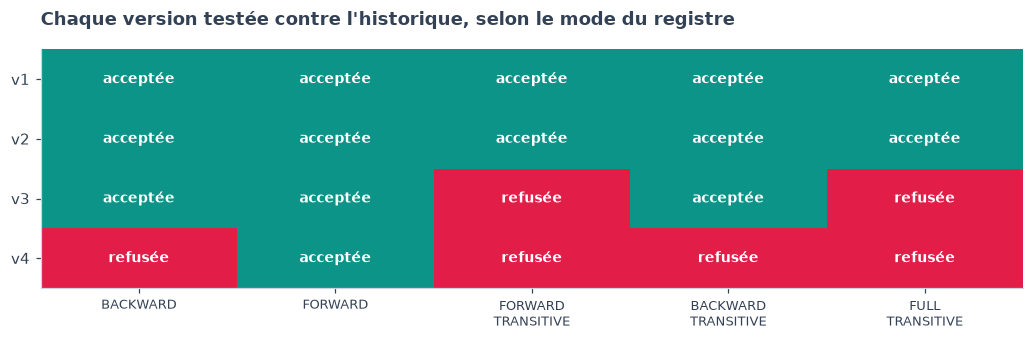

consommateur v1 lisant un message v3 : champ 'email' attendu par le lecteur, absent chez l'écrivain et sans défaut


In [12]:
fig, ax = plt.subplots(figsize=(9.5, 3.2))
vals = (verdicts == "acceptée").values.astype(float)
ax.imshow(vals, cmap="ddia_div", vmin=0, vmax=1, aspect="auto")
for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        ax.text(j, i, verdicts.values[i, j], ha="center", va="center", color="white", fontweight="bold", fontsize=9)
ax.set_xticks(range(vals.shape[1]), [c.replace("_", "\n") for c in verdicts.columns], fontsize=8.5)
ax.set_yticks(range(4), verdicts.index)
ax.grid(False)
ax.set_title("Chaque version testée contre l'historique, selon le mode du registre")
plt.tight_layout(); plt.show()
try:
    E.avro_decode(E.avro_encode({"id": 5}, V["v3"]), V["v3"], V["v1"])
except E.AvroError as exc:
    print("consommateur v1 lisant un message v3 :", exc)

(Pour comparer les modes sur la même histoire, chaque version est enregistrée même si le
mode l'aurait refusée.) Le tableau confirme : v3 passe en `FORWARD` mais pas en
`FORWARD_TRANSITIVE` ; v4 est refusée dans tous les modes qui protègent les lecteurs de
l'historique.

> **À retenir.** La compatibilité n'est pas transitive : une suite de changements
> compatibles deux à deux peut casser la compatibilité avec une version plus ancienne.
> Quand des données anciennes restent lisibles (rétention, relecture), il faut vérifier
> contre **toutes** les versions encore présentes.